<a href="https://colab.research.google.com/github/aledamelio/ML_Pavia/blob/main/06_Model_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Evaluation and Selection

__Model Evaluation__: we will see how to *quantitatevely* evaluate a trained learning model (classifier or regressor)

__Model Selection__: we will see how to *rigorously* choose between two or more candidate models for the same (classification or regression) learning task based on the available data


## Training and Test sets

To make an __unbiased__ evaluation of a trained model, we need to *test* it on __unseen data__ that were not used to train it.


To do this we train the model on a portion of the available data called __Training Set__.

After training, we measure the performance of the mode on the __Test Set__ composed of the remaining data.

We can easily __randomly__ split our data into a training and a test set using the function ```train_test_split``` from scikit-learn ([doc](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html))

In [ ]:
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):

    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))

    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)

    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class examples
    for idx, cl in enumerate(np.unique(y)):
      edge_kwargs = {} if markers[idx] == 'x' else {'edgecolor': 'black'}

      plt.scatter(
          x=X[y == cl, 0],
          y=X[y == cl, 1],
          alpha=0.8,
          c=colors[idx],
          marker=markers[idx],
          label=cl,
          **edge_kwargs
      )

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_circles

X, y = make_circles(factor=0.1, n_samples=500, noise=0.3, random_state=0)

colors = ('red', 'blue')
cmap = ListedColormap(colors)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, edgecolors='k')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)

print('Size of full dataset: ' + str(X.shape))
print('Size of training set: ' + str(X_train.shape))
print('Size of test set: ' + str(X_test.shape))

💡 ```stratify=y``` *makes sure every split has the same proportion of each class as the original dataset*

In [ ]:
print(sum(y_train==1)/len(y_train))
print(sum(y_train==1)/len(y_train))
print(sum(y_test==1)/len(y_test))

Addestriamo ora un modello di Regressione Logistica sul training set e valutiamo i risultati sl test set.

We will train a logistic regression classifier on the training set and measure its performance on the test set, unsing scikit-learn's __pipelines__

Applying the same pipeline to train and test data makes sure they are pre-processed in the same way. For example, standardized using the same mean and standard deviation (learned from the training data).

💡 *By default,* ```LogisticRegression``` *uses $\ell_2$ regularization.* ```C``` *(default $1.0$) is the inverse of the regularization coefficient. For unregularized logistic regression, set* ```C=np.inf``` ([doc](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html))

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

pipe_lr = make_pipeline(StandardScaler(),
                        LogisticRegression(random_state=1,C=1))

pipe_lr.fit(X_train, y_train)

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plot_decision_regions(X_train, y_train, classifier=pipe_lr)
plt.title('Training Set')
plt.subplot(1,2,2)
plot_decision_regions(X_test, y_test, classifier=pipe_lr)
plt.title('Test Set')
plt.show()

## Evaluating Classifiers

__Accuracy:__ the percentage of correctly classified samples (regardless of their class)

In [ ]:
train_acc = pipe_lr.score(X_train, y_train)
test_acc = pipe_lr.score(X_test, y_test)

#  Custom implementation
'''y_pred_train = pipe_lr.predict(X_train)
y_pred_test = pipe_lr.predict(X_test)
train_acc = np.sum(y_pred_train==y_train)/X_train.shape[0] * 100.
test_acc = np.sum(y_pred_test==y_test)/X_test.shape[0] * 100.'''

print('\nTraining Accuracy: %.2f' %(train_acc * 100.) + ' %')
print('Test Accuracy: %.2f' %(test_acc * 100.) + ' %')

How good is this result? What is the accuracy of a __dummy classifier__ that ignores the input and always predicts the most frequent clas in the training set?

💡 *There are other kinds of dummy classifiers, for example predicting class at random ([doc](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)). What they have in common is that they ignore the input variables*

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

train_acc_dummy = dummy_clf.score(X_train, y_train) * 100.
test_acc_dummy = dummy_clf.score(X_test, y_test) * 100.

print('\nTraining Accuracy Dummy Clf: %.2f' %train_acc_dummy + ' %')
print('Test Accuracy Dummy Clf: %.2f' %test_acc_dummy + ' %')

Let's try to increase accuracy using __polynomial features__

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly_lr = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),  # logistic regression is already including a bias parameter
    StandardScaler(),  # scale the features, not the input
    LogisticRegression(random_state=1, C=1, max_iter=1000)
)

poly_lr.fit(X_train, y_train)

poly_lr.fit(X_train, y_train)

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plot_decision_regions(X_train, y_train, classifier=poly_lr)
plt.title('Training Set')
plt.subplot(1,2,2)
plot_decision_regions(X_test, y_test, classifier=poly_lr)
plt.title('Test Set')
plt.show()

In [ ]:
print('\nTraining Accuracy: %.2f' %(poly_lr.score(X_train, y_train) * 100.) + ' %')
print('Test Accuracy: %.2f' %(poly_lr.score(X_test, y_test) * 100.) + ' %')

Much better, but we made a __methodological mistake__...can you see it?

### Other Performance Measures for Classifiers

__Confustion Matrix:__ not a scalar performance measure, but a report of the number of __true positive (TP), true negative (TN), false positive (FP), and false negative (FN)__ examples.

❗ *By default, the positive class is the one with label 0*

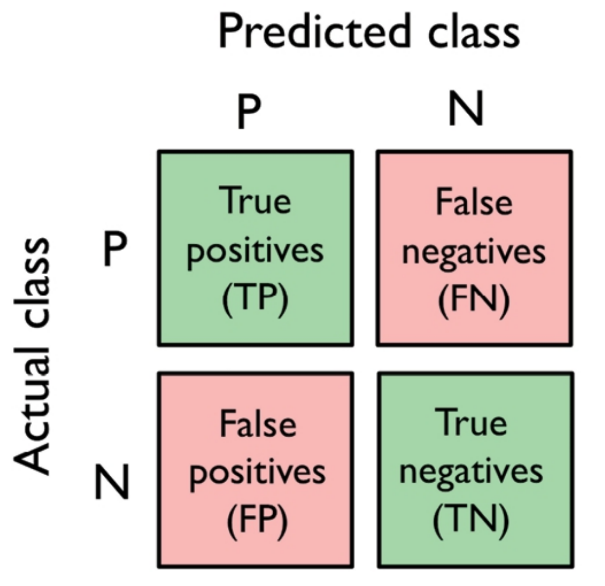

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predictions = poly_lr.predict(X_test)


# reordering labels to have class 1 as "positive"
cm = confusion_matrix(y_test, predictions, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[1, 0])

disp.plot()
plt.show()

Another definition of accuracy:

$$A C C=\frac{T P+T N}{F P+F N+T P+T N}$$

__Error Rate__ is the complement of accuracy (percentage of incorrectly classified examples):

$$E R R=\frac{F P+F N}{F P+F N+T P+T N} = 1 - ACC$$

Entrambe forniscono informazioni generali sul numero di esempi classificati correttamente/incorrettamente.

__Precision__ is the percentage of examples classified as positives that were correctlty classified

$$P R E=\frac{T P}{T P+F P}$$

__Recall__ is the percentage of positive examples that were correctly classified as such

$$R E C=\frac{T P}{T P+F N}$$

💡 *High __Precision__ means few false positives. High __Recall__ means few false negatives*

__F1 score:__ harmonic mean of Precision and Recall

$$F 1=2 \frac{P R E \times R E C}{P R E+R E C}$$

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

y_pred = poly_lr.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label=1):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label=1):.3f}")
print(f"F1:        {f1_score(y_test, y_pred, pos_label=1):.3f}")

### Precision-Recall (PR) Curve

Each point represents a different __probability cut-off__ in (0,1) for the positive class (by default, LogisticRegression uses a cutoff of $0.5$)

Increasing the threshold, less examples are classified as positive. Typically (but not necessarily) this increases precision and reduces recall

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

y_score = poly_lr.predict_proba(X_test)[:, 1]  # predicted probability of class 1

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_score,
    pos_label=1
)

plt.show()

## Evaluating Regressors

__Mean Squared Error:__ average squared difference between true and predicted target

$$M S E=\frac{1}{n} \sum_{i=1}^{n}\left(y^{(i)}-\hat{y}^{(i)}\right)^{2}$$

We take the California housing dataset, and try to predict median value from the input variable that is most correlated with it

In [ ]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

housing.keys()

df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['MedHouseVal'] = pd.Series(housing.target)

corr = df.corr()
corr.style.background_gradient(cmap='Greens').format(precision=2)

Let's use a __train-validation-test split__ this time (holdout validation)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

X = df[['MedInc']].values
y = df[['MedHouseVal']].values

# Just use train_test_split twice
# Reserve 20% for testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

# 25% of the remaining 80% gives 20% of the full dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=1
)

slr =  make_pipeline(StandardScaler(), LinearRegression())  # only the input is standardized
slr.fit(X_train, y_train)

train_MSE = mean_squared_error(y_train, slr.predict(X_train))
val_MSE = mean_squared_error(y_val, slr.predict(X_val))

print('\nTraining MSE: %.2f' %train_MSE)
print('Validation MSE: %.2f' %val_MSE)

In [ ]:
X_line = np.linspace(X_val.min(), X_val.max(), 200).reshape(-1, 1)
y_line = slr.predict(X_line)

plt.scatter(X_val[:, 0], y_val, alpha=0.7, label="Validation Samples")
plt.plot(X_line[:, 0], y_line, color="red", label="slr")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.legend()
plt.show()

Differently from accuracy, __MSE__ depends on the scale of the target values

In [ ]:
X = df[['MedInc']].values
y = df[['MedHouseVal']].values * 100

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=1
)

slr_resc = LinearRegression()
slr_resc.fit(X_train, y_train)

train_MSE = mean_squared_error(y_train, slr_resc.predict(X_train))
val_MSE = mean_squared_error(y_val, slr_resc.predict(X_val))

print('\nTraining MSE: %.2f' %train_MSE)
print('Validation MSE: %.2f' %val_MSE)

The __coefficient of determination__ ($R^2$) is MSE normalized by the variance of the target:

$$R^{2}=1-\frac{MSE}{TSS}$$

The $R^2$ is between $0$ and $1$ on the training set, but can be negative on the test set. $R^2 = 1$, denotes perfect prediction ($MSE = 0$)

In [ ]:
X = df[['MedInc']].values
y = df[['MedHouseVal']].values

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=1
)

slr =  make_pipeline(StandardScaler(), LinearRegression())  # only the input is standardized
slr.fit(X_train, y_train)

train_R2 = slr.score(X_train, y_train)
val_R2 = slr.score(X_val, y_val)

print('\nTraining R2: %.3f' %train_R2)
print('Validation R2: %.3f' %val_R2)

Let's compare this with the __dummy regressor__ that always predicts the average target. The (training) $R^2$ is zero by construction (why?)

In [ ]:
from sklearn.dummy import DummyRegressor

dummy_regr = DummyRegressor(strategy="mean")
dummy_regr.fit(X_train, y_train)

train_MSE = mean_squared_error(y_train, dummy_regr.predict(X_train))
val_MSE = mean_squared_error(y_val, dummy_regr.predict(X_val))

print('\nTraining MSE: %.2f' %train_MSE)
print('Validation MSE: %.2f' %val_MSE)

train_R2 = dummy_regr.score(X_train, y_train)
val_R2 = dummy_regr.score(X_val, y_val)

print('\nTraining R2: %.4f' %train_R2)
print('Validation R2: %.4f' %val_R2)

In [ ]:
X_line = np.linspace(X_val.min(), X_val.max(), 200).reshape(-1, 1)
y_line = dummy_regr.predict(X_line)

plt.scatter(X_val[:, 0], y_val, alpha=0.7, label="Validation Samples")
plt.plot(X_line[:, 0], y_line, color="red", label="dummy")
plt.xlabel("MedInc")
plt.ylabel("MEDV")
plt.legend()
plt.show()

### Holdout Validation

Let's use the __validation set__ to compare polynomial feature maps of various degree

In [ ]:
features = ["MedInc", "HouseAge", "Latitude", "Longitude"]
X = df[features].values
y = df["MedHouseVal"].values

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=1
)

training_scores = []
validation_scores = []
degrees = range(1, 11)

for d in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    training_scores.append(model.score(X_train, y_train))
    validation_scores.append(model.score(X_val, y_val))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

ax.plot(
    degrees, training_scores,
    color="tab:blue", marker="o", markersize=5,
    linewidth=2, label="Training"
)
ax.plot(
    degrees, validation_scores,
    color="tab:orange", marker="s", markersize=5,
    linewidth=2, label="Validation"
)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Polynomial degree", fontsize=12)
ax.set_ylabel(r"$R^2$", fontsize=12)
ax.set_xticks(list(degrees))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_ylim(-0.1, 1.1)

plt.show()



We select the model with the highest __validation__ $R^2$, re-train it *on all non-test data*, and finally measure its performance on the __test set__

In [ ]:
best_degree = int(np.argmax(validation_scores)) + 1
print("Chosen degree:", best_degree)
R2_val = validation_scores[best_degree - 1]
print("Validation R2:", R2_val)

model = make_pipeline(
        PolynomialFeatures(degree=best_degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )


# Re-train the chosen model on all training+validation data
model.fit(X_trainval, y_trainval)

# Evaluate final trained model on the test data
R2_test = model.score(X_test, y_test)
print("Test R2 (after re-training): ", R2_test)

## K-fold Cross-Validation

- Split the dataset into __training and test__ set
- Divide the training set into $k$ __folds__ approximately of the same size
- Train the model on $k-1$ folds and validate on the remaining one
- Repeat $k$ times changing the validation fold

The performance estimate is the average of the $k$ validation scores computed on the folds.

The choice of $k$ depends mostly on the size of the dataset (larger $k$ for smaller datasets)

A typical choice is $k=10$.

### K-fold cross-validation in Python

We can use the _StratifiedKFold_ class from _sklearn_.

_Stratified_ means that each fold will (approximately) preserve the original proportion of classes

Let's try it on our quadratic classifier for the Circles dataset

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split

X, y = make_circles(factor=0.1, n_samples=500, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)

kfold = StratifiedKFold(n_splits=10).split(X_train, y_train)  # k = 10

scores = []
for k, (train, val) in enumerate(kfold):
    poly_lr.fit(X_train[train], y_train[train])
    score = poly_lr.score(X_train[val], y_train[val])
    scores.append(score)
    print('Fold: %2d, Acc: %.2f' % (k+1, score))

print('\nCV accuracy: %.2f +/- %.2f' % (np.mean(scores), np.std(scores)))

The same result can be obtained with __cross_val_score__:

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(estimator=poly_lr,
                         X=X_train,
                         y=y_train,
                         cv=10)
scores = np.array(scores)
print('CV accuracy: %.2f +/- %.2f' % (np.mean(scores), np.std(scores)))

In [ ]:
# Re-train the chosen model on all training data
poly_lr.fit(X_train, y_train)

# Evaluate final trained model on the test data
acc_test = poly_lr.score(X_test, y_test)
print("Test Accuracy (after re-training): ", acc_test)

Let's try CV on the California housing regression problem.
This time we use scikit-learn to plot __validation curves__ (training and validation score for each polynomial degree)

We will use $K=5$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

housing = fetch_california_housing(as_frame=True)
X = housing.data[["MedInc", "HouseAge", "Latitude", "Longitude"]]
y = housing.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

degrees = np.arange(1, 11)
model = make_pipeline(
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    LinearRegression()
)

train_scores, val_scores = validation_curve(
    model, X_train, y_train,
    param_name="polynomialfeatures__degree",
    param_range=degrees,
    cv=KFold(n_splits=5, shuffle=True, random_state=1),
    scoring="r2"
)

training_scores = train_scores.mean(axis=1)
validation_scores = val_scores.mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for scores, label, color in [
    (train_scores, "Training", "tab:blue"),
    (val_scores, "Validation", "tab:orange")
]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(degrees, mean, "o-", color=color, label=label)
    ax.fill_between(degrees, mean - std, mean + std, color=color, alpha=0.15)

ax.set(xlabel="Polynomial degree", ylabel=r"$R^2$", xticks=degrees)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Exercise
Try to use different values of $K$ (number of folds) for the California housing problem. What do you observe?

### Unbalanced classes

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=(30, 370), noise=0.3, random_state=0)

colors = ('red', 'blue')
cmap = ListedColormap(colors)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, edgecolors='k')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=123)
lr.fit(X_train, y_train)

y_pred = lr.predict(X_train)

plot_decision_regions(X_train, y_train, classifier=lr)
plt.legend(loc='upper left')
plt.tight_layout()

Class 0 is much less represented in the dataset: the classifier will tend to predict 1 more often

In [ ]:
y_pred_test = lr.predict(X_test)

In [ ]:
print('Accuracy: %.3f' % accuracy_score(y_true=y_test, y_pred=y_pred_test))
print('Precision: %.3f' % precision_score(y_true=y_test, y_pred=y_pred_test, pos_label=0))#, zero_division=0))
print('Recall: %.3f' % recall_score(y_true=y_test, y_pred=y_pred_test, pos_label=0))
print('F1: %.3f' % f1_score(y_true=y_test, y_pred=y_pred_test, pos_label=0))

The classifier has __high accuracy__, but low precision and recall. Accuracy is less reliable with unbalanced classes (why?)

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

train_acc_dummy = dummy_clf.score(X_train, y_train) * 100.
test_acc_dummy = dummy_clf.score(X_test, y_test) * 100.

print('Accuracy Dummy Clf: %.2f' %test_acc_dummy + ' %')